# Name   : Shaik Althaf Basha
# Roll No: 23102A010281
# Section: B4
# Branch : AIML
# Name Of The Experiment: CUSTOMER PERSONALITY ANALYSIS USING K-MEANS

In [1]:
# AIM:
# ----
# To analyze customer purchasing behavior and divide customers
# into different groups (clusters) using the K-Means clustering
# algorithm.
#
# K-Means is an Unsupervised Machine Learning algorithm.
# It groups similar customers together without predefined labels.
#
# ==============================================================


# ==============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
# ==============================================================
# STEP 2: LOAD THE DATASET
# ==============================================================

# IMPORTANT:
# Use the RAW GitHub URL, not the GitHub /blob/ webpage URL.

url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"

In [3]:
# Read CSV file
df = pd.read_csv(url)

In [4]:
# ==============================================================
# STEP 3: DISPLAY DATASET
# ==============================================================

print("=" * 70)
print("FIRST FIVE RECORDS")
print("=" * 70)

print(df.head())


print("\n")
print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

df.info()


print("\n")
print("=" * 70)
print("DATASET SHAPE")
print("=" * 70)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])


print("\n")
print("=" * 70)
print("COLUMN NAMES")
print("=" * 70)

print(df.columns.tolist())


FIRST FIVE RECORDS
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


DATASET SHAPE
Rows    : 200
Columns

In [5]:
# ==============================================================
# STEP 4: CHECK MISSING VALUES
# ==============================================================

print("\n")
print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(df.isnull().sum())



MISSING VALUES
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [6]:
# ==============================================================
# STEP 5: CHECK DUPLICATE RECORDS
# ==============================================================

print("\n")
print("=" * 70)
print("DUPLICATE RECORDS")
print("=" * 70)

print("Number of duplicate rows:", df.duplicated().sum())



DUPLICATE RECORDS
Number of duplicate rows: 0


In [7]:
# ==============================================================
# STEP 6: SELECT FEATURES FOR CLUSTERING
# ==============================================================

# We use:
#
# Annual Income (k$)
# Spending Score (1-100)
#
# These two variables are commonly used for customer segmentation.

X = df[
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]


print("\n")
print("=" * 70)
print("SELECTED FEATURES")
print("=" * 70)

print(X.head())



SELECTED FEATURES
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [8]:
# ==============================================================
# STEP 7: STANDARDIZE THE FEATURES
# ==============================================================

# StandardScaler converts features into a common scale.
#
# This is useful because K-Means uses distance calculations.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


print("\n")
print("=" * 70)
print("STANDARDIZED FEATURES")
print("=" * 70)

print(X_scaled[:5])



STANDARDIZED FEATURES
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


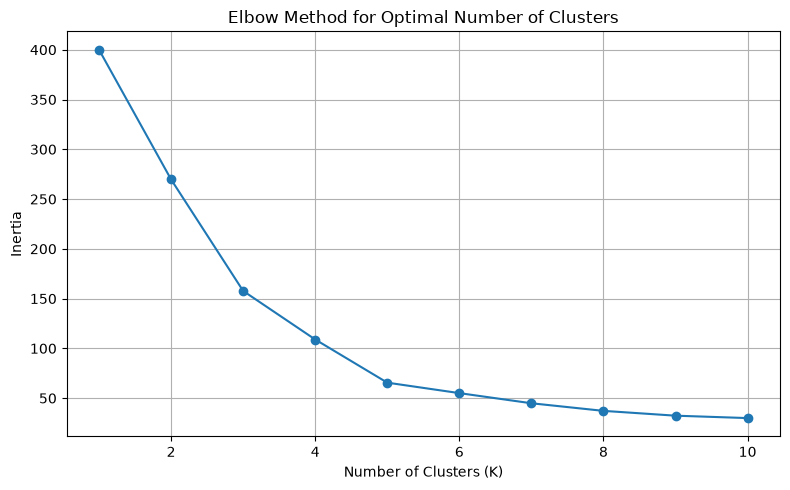

In [11]:
# The Elbow Method helps determine a suitable number of clusters.

inertia = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)


# Plot Elbow Curve

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.grid(True)

plt.tight_layout()

plt.savefig("elbow_method.png")

plt.show()

In [12]:
# ==============================================================
# STEP 9: CREATE K-MEANS MODEL
# ==============================================================

# Based on the elbow method, we select 5 clusters.

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

In [13]:
# ==============================================================
# STEP 10: TRAIN MODEL AND ASSIGN CLUSTERS
# ==============================================================

# fit_predict():
#
# fit()         -> trains the K-Means model
# predict()     -> assigns cluster numbers
#
# fit_predict() performs both operations.

df["Cluster"] = kmeans.fit_predict(X_scaled)

In [14]:
# ==============================================================
# STEP 11: DISPLAY CUSTOMER CLUSTERS
# ==============================================================

print("\n")
print("=" * 70)
print("CUSTOMER CLUSTERS")
print("=" * 70)

print(
    df[
        [
            "CustomerID",
            "Annual Income (k$)",
            "Spending Score (1-100)",
            "Cluster"
        ]
    ].head(20)
)



CUSTOMER CLUSTERS
    CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0            1                  15                      39        4
1            2                  15                      81        2
2            3                  16                       6        4
3            4                  16                      77        2
4            5                  17                      40        4
5            6                  17                      76        2
6            7                  18                       6        4
7            8                  18                      94        2
8            9                  19                       3        4
9           10                  19                      72        2
10          11                  19                      14        4
11          12                  19                      99        2
12          13                  20                      15        4
13          14              

In [15]:
# ==============================================================
# STEP 12: DISPLAY CLUSTER CENTERS
# ==============================================================

# Cluster centers are initially calculated
# in standardized feature space.
#
# Convert them back to the original scale
# for easier interpretation.

cluster_centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    cluster_centers,
    columns=[
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
)

centers_df.index.name = "Cluster"


print("\n")
print("=" * 70)
print("CLUSTER CENTERS")
print("=" * 70)

print(centers_df)



CLUSTER CENTERS
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043


In [16]:
# ==============================================================
# STEP 13: COUNT CUSTOMERS IN EACH CLUSTER
# ==============================================================

print("\n")
print("=" * 70)
print("CUSTOMER COUNT PER CLUSTER")
print("=" * 70)

print(df["Cluster"].value_counts().sort_index())



CUSTOMER COUNT PER CLUSTER
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [17]:
# ==============================================================
# STEP 14: CUSTOMER SEGMENT SUMMARY
# ==============================================================

summary = df.groupby("Cluster")[
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].mean()

summary["Customer Count"] = df["Cluster"].value_counts()

summary = summary.sort_index()


print("\n")
print("=" * 70)
print("CUSTOMER SEGMENT SUMMARY")
print("=" * 70)

print(summary)



CUSTOMER SEGMENT SUMMARY
         Annual Income (k$)  Spending Score (1-100)  Customer Count
Cluster                                                            
0                 55.296296               49.518519              81
1                 86.538462               82.128205              39
2                 25.727273               79.363636              22
3                 88.200000               17.114286              35
4                 26.304348               20.913043              23


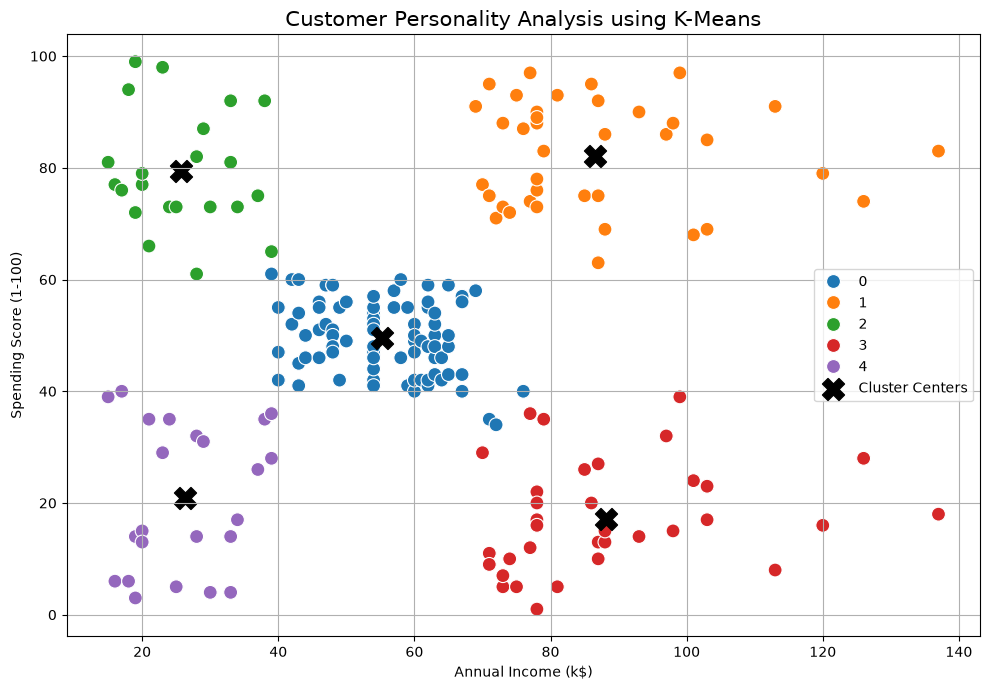

In [18]:
# ==============================================================
# STEP 15: VISUALIZE CUSTOMER SEGMENTS
# ==============================================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100
)


# Plot cluster centers

plt.scatter(
    cluster_centers[:, 0],
    cluster_centers[:, 1],
    marker="X",
    s=250,
    c="black",
    label="Cluster Centers"
)


plt.title(
    "Customer Personality Analysis using K-Means",
    fontsize=15
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "customer_segments_kmeans.png",
    dpi=300
)

plt.show()


In [19]:
# ==============================================================
# STEP 16: SAVE CLUSTERED DATASET
# ==============================================================

df.to_csv(
    "Mall_Customers_Clustered.csv",
    index=False
)

In [20]:
# ==============================================================
# STEP 17: FINAL MESSAGE
# ==============================================================

print("\n")
print("=" * 70)
print("CUSTOMER SEGMENTATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Number of Clusters :", kmeans.n_clusters)

print("Clustered dataset saved as:")
print("Mall_Customers_Clustered.csv")

print("\nGraphs saved as:")
print("1. elbow_method.png")
print("2. customer_segments_kmeans.png")



CUSTOMER SEGMENTATION COMPLETED SUCCESSFULLY
Number of Clusters : 5
Clustered dataset saved as:
Mall_Customers_Clustered.csv

Graphs saved as:
1. elbow_method.png
2. customer_segments_kmeans.png


In [ ]:
f
